In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Level A — Easy

## A1. Data Types & Attributes

In [12]:
df = pd.read_csv('Penguin_Species_Prediction_Dataset.csv')
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,41.1,18.4,195.0,3886.0,Female
1,Gentoo,Biscoe,50.0,15.4,217.0,4303.0,Male
2,Gentoo,Biscoe,50.0,15.1,220.0,4954.0,Female
3,Chinstrap,Dream,48.7,19.0,196.0,3739.0,Male
4,Adelie,Dream,39.0,17.8,187.0,3607.0,Male


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            1000 non-null   str    
 1   island             1000 non-null   str    
 2   culmen_length_mm   990 non-null    float64
 3   culmen_depth_mm    990 non-null    float64
 4   flipper_length_mm  990 non-null    float64
 5   body_mass_g        990 non-null    float64
 6   sex                990 non-null    str    
dtypes: float64(4), str(3)
memory usage: 54.8 KB


1. **`species` (Nominal):** Categorical variable representing the species of the penguin (Adelie, Chinstrap, Gentoo).
2. **`island` (Nominal):** Categorical variable indicating the island where the observation took place (Torgersen, Biscoe, Dream).
3. **`sex` (Nominal):** Binary categorical variable indicating the biological sex (Male, Female).
4. **`culmen_length_mm` (Continuous):** Numeric measurement of the culmen length in millimeters.
5. **`culmen_depth_mm` (Continuous):** Numeric measurement of the culmen depth in millimeters.
6. **`flipper_length_mm` (Continuous):** Measurement of flipper length in millimeters. 
7. **`body_mass_g` (Continuous):** Measurement of body mass in grams.

In [14]:
numeric_cols = df.select_dtypes(include=[np.number]).columns

stats = {}

for col in numeric_cols:
    s = df[col].dropna()
    mean_val = s.mean()
    median_val = s.median()
    mode_val = s.mode()[0]
    ptp_range = s.max() - s.min()
    var_val = s.var()
    std_val = s.std()
    q25, q75 = s.quantile(0.25), s.quantile(0.75)
    iqr_val = q75 - q25
    
    stats[col] = {
        'Mean': mean_val,
        'Median': median_val,
        'Mode': mode_val,
        'Range': ptp_range,
        'Variance': var_val,
        'Std Dev': std_val,
        'IQR': iqr_val
    }

stats_df = pd.DataFrame(stats)
stats_df.round(2)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
Mean,43.82,17.34,199.22,4103.31
Median,43.80,17.80,195.00,3882.00
Mode,38.30,18.20,189.00,3318.00
Range,23.60,8.40,60.00,3487.00
Variance,28.20,3.17,173.49,497497.17
Std Dev,5.31,1.78,13.17,705.33
IQR,9.30,2.90,23.00,1001.00


1. **`culmen_length_mm`:**
   - **Central Tendency:** The mean (43.82mm) and median (43.80mm) are practically identical, indicating a balanced, symmetric distribution.
   - **Dispersion:** Standard deviation is 5.31mm with an IQR of 9.30mm, showing moderate variability across different penguin species.

2. **`culmen_depth_mm`:**
   - **Central Tendency:** Mean (17.34mm) is slightly lower than the median (17.80mm), suggesting a mild left skewness due to Gentoo penguins having shallower culmens.
   - **Dispersion:** Shows the lowest variability among all features (Std Dev = 1.78mm, IQR = 2.90mm).

3. **`flipper_length_mm`:**
   - **Central Tendency:** Mean (199.22mm) is higher than the median (195.00mm), showing a slight right skewness driven by larger Gentoo penguins.
   - **Dispersion:** Standard deviation is 13.17mm and IQR is 23.00mm.

4. **`body_mass_g`:**
   - **Central Tendency:** Mean (4103.31g) exceeds the median (3882.00g), indicating positive skewness caused by heavier male Gentoo individuals.
   - **Dispersion:** Operates on a much larger numerical scale, with a variance of 497,497.17g^2, standard deviation of 705.33g, and an IQR of 1001.00g.

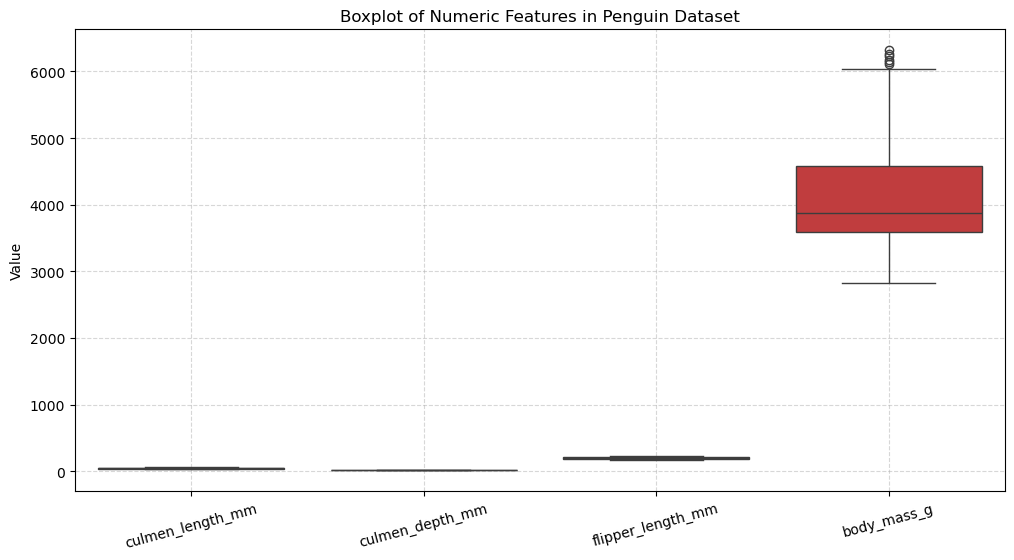

In [15]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric_cols])
plt.title("Boxplot of Numeric Features in Penguin Dataset")
plt.ylabel("Value")
plt.xticks(rotation=15)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [16]:
for col in numeric_cols:
    s = df[col].dropna()
    q25, q75 = s.quantile(0.25), s.quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    
    outliers = s[(s < lower_bound) | (s > upper_bound)]
    print(f"{col}: {len(outliers)} outliers: {outliers.tolist()}")

culmen_length_mm: 0 outliers: []
culmen_depth_mm: 0 outliers: []
flipper_length_mm: 0 outliers: []
body_mass_g: 6 outliers: [6148.0, 6114.0, 6258.0, 6176.0, 6317.0, 6237.0]



Due to the magnitude of `body_mass_g` (ranging from 2800 to >6000g), its box dominates the plot visual scale, while `culmen_length_mm`, `culmen_depth_mm`, and `flipper_length_mm` appear compressed at the bottom near zero.

 **`body_mass_g`:** **6 suspected outliers** detected above the upper threshold: `[6114.0, 6148.0, 6176.0, 6237.0, 6258.0, 6317.0]` grams.
 These 6 high body mass values represent unusually large adult male Gentoo penguins. While statistically flagged as outliers relative to the entire population, they represent natural biological variance rather than measurement errors or data corruption.

## A3. Handling Missing Data

In [17]:
df.isnull().sum()

species               0
island                0
culmen_length_mm     10
culmen_depth_mm      10
flipper_length_mm    10
body_mass_g          10
sex                  10
dtype: int64

In [18]:

from sklearn.impute import KNNImputer
missing_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

orig_stats = df[missing_cols].agg(['mean', 'std']).T
orig_stats.columns = ['Orig_Mean', 'Orig_Std']

# Constant Imputation
df_const = df[missing_cols].fillna(0)
const_stats = df_const.agg(['mean', 'std']).T
const_stats.columns = ['Const_Mean', 'Const_Std']

# Mean Imputation
df_mean = df[missing_cols].fillna(df[missing_cols].mean())
mean_stats = df_mean.agg(['mean', 'std']).T
mean_stats.columns = ['Mean_Imp_Mean', 'Mean_Imp_Std']

# KNN Predictive Imputation
knn_imputer = KNNImputer(n_neighbors=5)
df_knn = pd.DataFrame(knn_imputer.fit_transform(df[missing_cols]), columns=missing_cols)
knn_stats = df_knn.agg(['mean', 'std']).T
knn_stats.columns = ['KNN_Mean', 'KNN_Std']

comparison_df = pd.concat([orig_stats, const_stats, mean_stats, knn_stats], axis=1)
comparison_df.round(2)

,Orig_Mean,Orig_Std,Const_Mean,Const_Std,Mean_Imp_Mean,Mean_Imp_Std,KNN_Mean,KNN_Std
culmen_length_mm,43.82,5.31,43.38,6.85,43.82,5.28,43.81,5.29
culmen_depth_mm,17.34,1.78,17.16,2.47,17.34,1.77,17.34,1.78
flipper_length_mm,199.22,13.17,197.23,23.77,199.22,13.11,199.22,13.12
body_mass_g,4103.31,705.33,4062.28,812.02,4103.31,701.80,4102.99,703.59


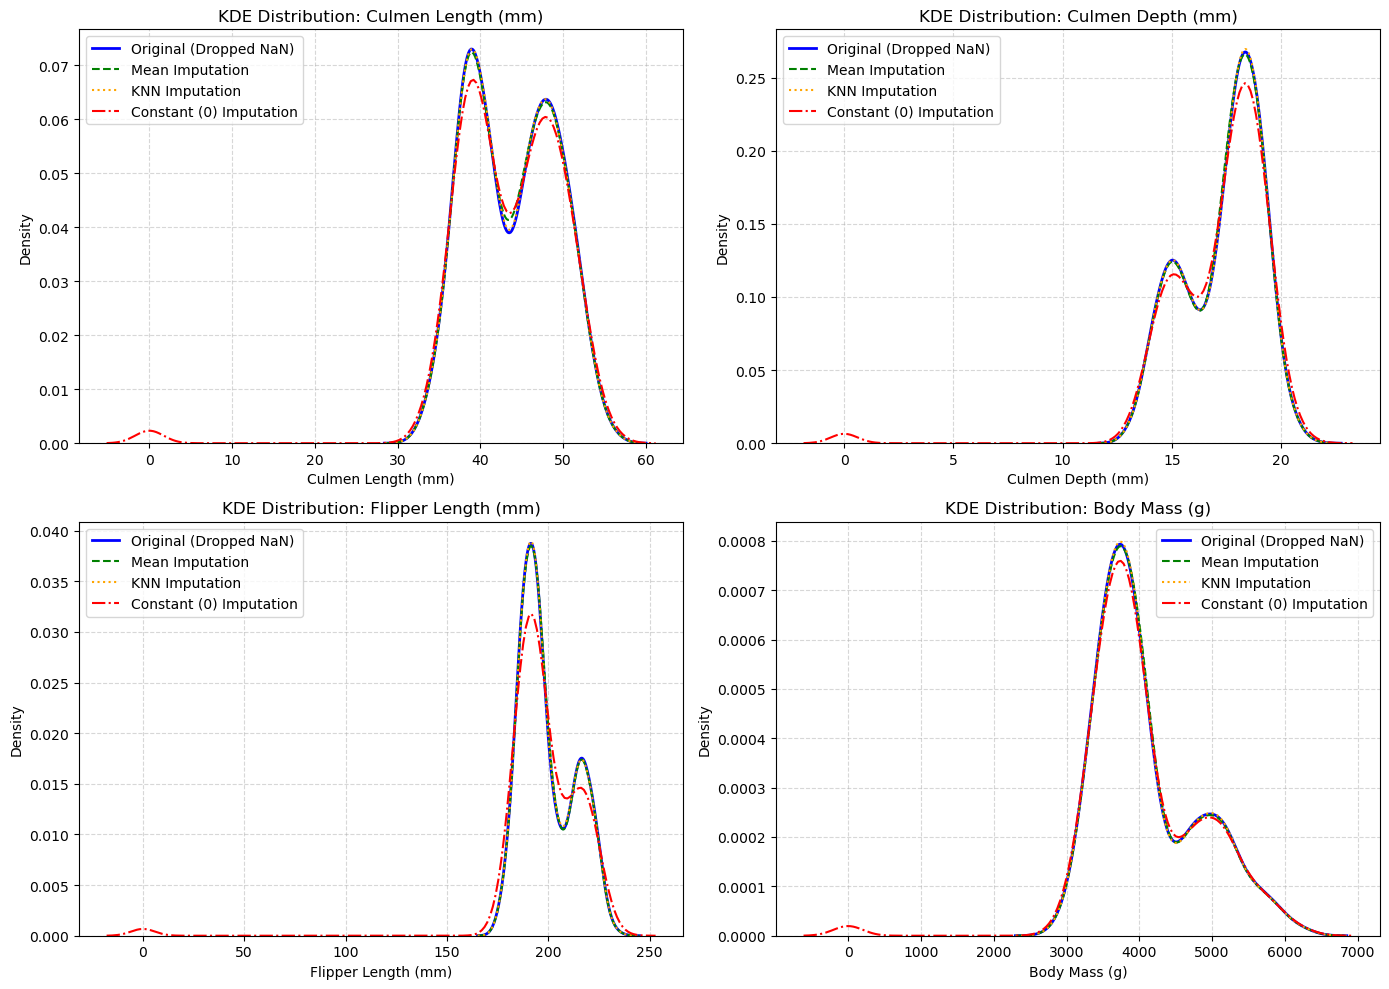

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

titles = {
    'culmen_length_mm': 'Culmen Length (mm)',
    'culmen_depth_mm': 'Culmen Depth (mm)',
    'flipper_length_mm': 'Flipper Length (mm)',
    'body_mass_g': 'Body Mass (g)'
}

for i, col in enumerate(missing_cols):
    sns.kdeplot(df[col].dropna(), ax=axes[i], label='Original (Dropped NaN)', color='blue', linewidth=2)
    sns.kdeplot(df_mean[col], ax=axes[i], label='Mean Imputation', color='green', linestyle='--')
    sns.kdeplot(df_knn[col], ax=axes[i], label='KNN Imputation', color='orange', linestyle=':')
    sns.kdeplot(df_const[col], ax=axes[i], label='Constant (0) Imputation', color='red', linestyle='-.')
    
    axes[i].set_title(f'KDE Distribution: {titles[col]}')
    axes[i].set_xlabel(titles[col])
    axes[i].set_ylabel('Density')
    axes[i].legend()
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

1. **Constant Imputation (0):**
   - **Effect on Mean:** Significantly shifts the mean downward for all features (`body_mass_g` drops from 4103.31g to 4062.28g, and `flipper_length_mm` drops from 199.22mm to 197.23mm).
   - **Effect on Standard Deviation:** Artificially inflates the standard deviation across all columns (`body_mass_g` standard deviation jumps from 705.33 to 812.02, and `flipper_length_mm` jumps from 13.17 to 23.77) because zeroes create extreme artificial outliers relative to normal penguin measurements.
   - **Assessment:** Highly distortive for physical features.

2. **Mean Imputation:**
   - **Effect on Mean:** Perfectly preserves the original population mean (`43.82`, `17.34`, `199.22`, `4103.31`).
   - **Effect on Standard Deviation:** Slightly underestimates/reduces the standard deviation across all variables (`body_mass_g` drops from 705.33 to 701.80, `flipper_length_mm` drops from 13.17 to 13.11) because adding central values decreases overall variance.
   - **Assessment:** Simple and stable for overall metrics, but reduces sample variability.

3. **Predictive Imputation (KNN, k=5):**
   - **Effect on Mean:** Preserves the mean almost perfectly with minimal deviation (`43.81` vs `43.82` for culmen length; `4102.99` vs `4103.31` for body mass).
   - **Effect on Standard Deviation:** Preserves the original standard deviation better than Mean imputation (`703.59` vs `701.80` for body mass, compared to original 705.33).
   - **Assessment:** Best method for preserving multivariate relationships and variance structure.

# Level B — Medium

## B1. Normalization & Standardization

In [39]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scale_cols = ['culmen_length_mm', 'body_mass_g']
df_scale = df_knn[scale_cols].copy()

# Min-Max
scaler_minmax = MinMaxScaler()
df_minmax = pd.DataFrame(
    scaler_minmax.fit_transform(df_scale),
    columns=[f"{col}_minmax" for col in scale_cols]
)

# Z-score
scaler_std = StandardScaler()
df_std = pd.DataFrame(
    scaler_std.fit_transform(df_scale),
    columns=[f"{col}_std" for col in scale_cols]
)

pd.concat([df_minmax, df_std], axis=1).head()

,culmen_length_mm_minmax,body_mass_g_minmax,culmen_length_mm_std,body_mass_g_std
0,0.368644,0.302839,-0.512957,-0.308560
1,0.745763,0.422426,1.170271,0.284411
2,0.745763,0.609120,1.170271,1.210128
3,0.690678,0.260683,0.924406,-0.517593
4,0.279661,0.222828,-0.910123,-0.705296


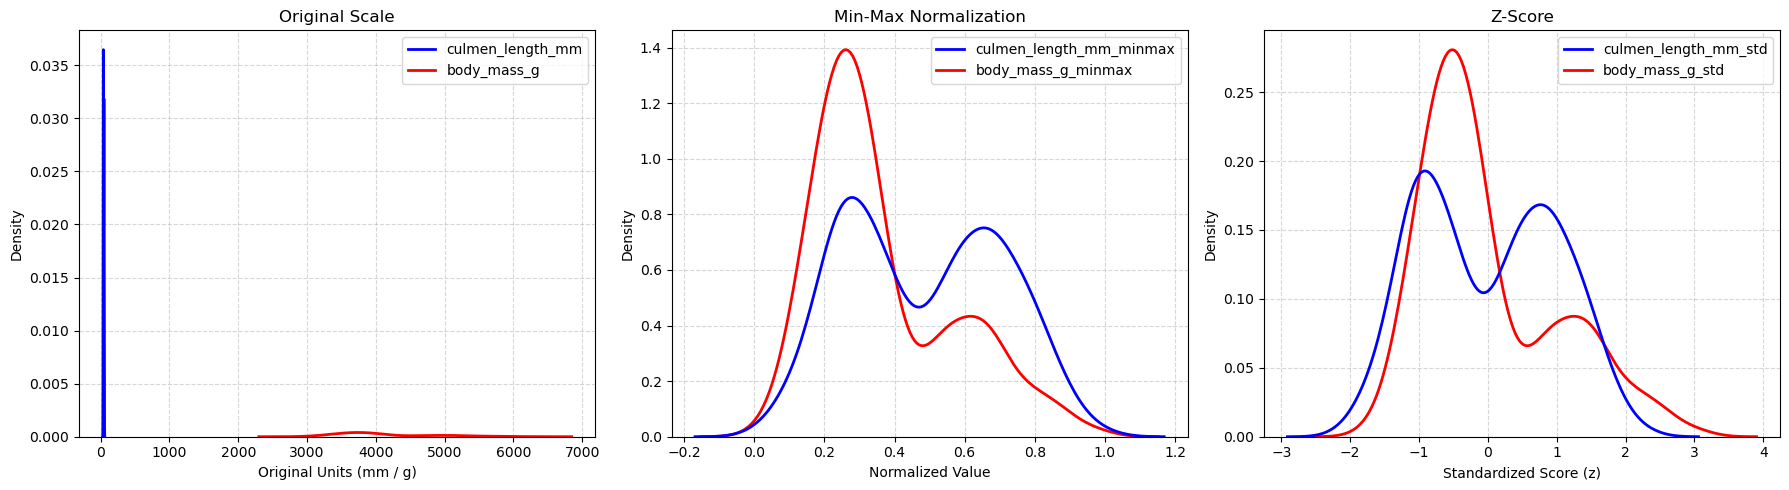

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Original
sns.kdeplot(data=df_scale, ax=axes[0], palette=['blue', 'red'], linewidth=2)
axes[0].set_title("Original Scale")
axes[0].set_xlabel("Original Units (mm / g)")
axes[0].grid(True, linestyle='--', alpha=0.5)

# Min-Max
sns.kdeplot(data=df_minmax, ax=axes[1], palette=['blue', 'red'], linewidth=2)
axes[1].set_title("Min-Max Normalization")
axes[1].set_xlabel("Normalized Value")
axes[1].grid(True, linestyle='--', alpha=0.5)

# Z-score
sns.kdeplot(data=df_std, ax=axes[2], palette=['blue', 'red'], linewidth=2)
axes[2].set_title("Z-Score")
axes[2].set_xlabel("Standardized Score (z)")
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### Interpretation & Method Guidance

1. **Impact on Distributions:**
   - **Original:** `body_mass_g` operates on thousands, making `culmen_length_mm` visually invisible on a shared plot.
   - **Min-Max Scaling:** Successfully compresses both attributes into identical bounded intervals [0, 1]. The shape of the distribution is preserved completely, but bounded bounds make it sensitive to extreme outliers.
   - **Z-Score Scaling:** Rescales values around 0 with unit variance. Outliers lie further out beyond 3, preserving true variance without squishing inliers into a narrow interval.

2. **When to Prefer Which Method:**
   - **Min-Max Normalization** is preferable when algorithms require bounded input ranges (e.g., Neural Networks, Image Intensity Values) or distance-based algorithms where features do not assume Gaussian distributions (e.g., k-NN without outliers).
   - **Z-Score Standardization** is preferable for models assuming normally distributed input data, distance/gradient-based optimization methods (e.g., Support Vector Machines, Logistic/Linear Regression, Principal Component Analysis), or datasets containing significant outliers.